# 04 — Neural network (MLP)

A small multi-layer perceptron (MLP) is trained on the same training set, the same TF-IDF features and the same grouped 5-fold cross-validation as notebook 03, so it can be compared fairly with logistic regression and gradient boosting. The test set is not used in this notebook.

## Setup

In [1]:
import sys
import time
import warnings
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.exceptions import ConvergenceWarning

from src import config

In [2]:
train = pd.read_csv(config.PROCESSED_DIR / "train.csv")
PERIODS = ["pre-1750", "1750-1799", "1800-1849", "1850-1899", "1900-1918"]

X = train["excerpt"]
y = train["period"]
groups = train["group"]

print("Train:", train.shape)
train["period"].value_counts().reindex(PERIODS)

Train: (288, 6)


period
pre-1750     38
1750-1799    47
1800-1849    56
1850-1899    71
1900-1918    76
Name: count, dtype: int64

## Cross-validation setup

The folds are exactly the same as in notebook 03 (same seed). A neural network also gives different results depending on its random starting weights, so every MLP setting is run with **3 seeds** (0, 1, 2). The seed changes only the network, not the folds. The reference scores for logistic regression and boosting are read from notebook 03's saved results, so they don't need re-running.

In [3]:
cv = StratifiedGroupKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}
SEEDS = [0, 1, 2]

def tfidf():
    return TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z]{2,}\b", min_df=10)

def evaluate_seeds(name, make_model):
    """Run the same 5 folds once per seed; report the average over seeds."""
    runs = []
    for seed in SEEDS:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            s = cross_validate(make_model(seed), X, y, groups=groups, cv=cv,
                               scoring=scoring, return_estimator=True, return_train_score=True)
        runs.append(s)
    seed_means = [r["test_macro_f1"].mean() for r in runs]
    return {
        "model": name,
        "macro_f1": np.mean(seed_means),
        "fold_std": np.mean([r["test_macro_f1"].std() for r in runs]),
        "seed_std": np.std(seed_means),
        "train_macro_f1": np.mean([r["train_macro_f1"].mean() for r in runs]),
        "accuracy": np.mean([r["test_accuracy"].mean() for r in runs]),
        "fit_time_s": np.mean([r["fit_time"].mean() for r in runs]),
        "seed_macro_f1": np.round(seed_means, 3).tolist(),
        "estimators": [e for r in runs for e in r["estimator"]],
    }

reference = pd.read_csv(config.ROOT / "reports" / "experiment_results.csv")
reference = reference[reference["model"].isin(["LogReg C=100", "Boosting rounds=400"])]
reference[["model", "macro_f1", "macro_f1_std", "accuracy", "fit_time_s"]]

,model,macro_f1,macro_f1_std,accuracy,fit_time_s
4,LogReg C=100,0.459699,0.067164,0.458923,2.951035
27,Boosting rounds=400,0.505606,0.063637,0.496975,9.818003


## MLP design

| Choice | Setting | Reason |
|---|---|---|
| Input | TF-IDF (same as notebook 03), then `StandardScaler(with_mean=False)` | Neural networks train better when inputs are on a similar scale; `with_mean=False` keeps the data sparse |
| Architecture | 1 hidden layer of 64 units | Small, because there are only ~230 training books per fold |
| Activation | ReLU | Standard default; trains quickly |
| Output / loss | Softmax over 5 periods, cross-entropy (log-loss) | Standard for multi-class classification |
| Optimiser | Adam, learning rate 0.001 | Standard default |
| Batch size | 32 | Several weight updates per epoch with a small dataset |
| Regularisation | L2 penalty `alpha` | Varied below |
| Stopping rule | Early stopping: 10% of each training fold is held back; training stops when its score has not improved for 10 epochs (max 200) | Prevents overfitting without choosing the epoch count by hand |

Limitation: early stopping's 10% hold-out is a random split, not grouped by author, so it may stop slightly late. This only affects when training stops; the reported scores still come from the author-grouped validation folds.

In [4]:
def mlp(hidden=(64,), alpha=1e-4):
    def make(seed):
        return make_pipeline(
            tfidf(),
            StandardScaler(with_mean=False),
            MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam",
                          alpha=alpha, batch_size=32, learning_rate_init=0.001,
                          max_iter=200, early_stopping=True, validation_fraction=0.1,
                          n_iter_no_change=10, random_state=seed),
        )
    return make

mlp_results = []
start = time.time()
mlp_results.append(evaluate_seeds("MLP 64 units, alpha=1e-4", mlp()))
print(f"Took {time.time() - start:.0f} s")

pd.DataFrame(mlp_results).drop(columns="estimators")

Took 106 s


,model,macro_f1,fold_std,seed_std,train_macro_f1,accuracy,fit_time_s,seed_macro_f1
0,"MLP 64 units, alpha=1e-4",0.467459,0.064554,0.026453,0.932694,0.473624,5.557703,"[0.46, 0.44, 0.503]"


## Capacity and regularisation settings

The first setting (64 units, `alpha=1e-4`) is changed one thing at a time:
- **Capacity:** a smaller (16 units) and a larger (256 units) hidden layer.
- **Regularisation:** a stronger L2 penalty (`alpha` = 0.01 and 1), which keeps the weights small.

`train_macro_f1` is the score on the books the network was trained on. A large gap between it and the validation `macro_f1` means the network is overfitting (memorising the training books).

In [5]:
settings = [
    ("MLP 16 units, alpha=1e-4", mlp(hidden=(16,))),
    ("MLP 256 units, alpha=1e-4", mlp(hidden=(256,))),
    ("MLP 64 units, alpha=0.01", mlp(alpha=0.01)),
    ("MLP 64 units, alpha=1", mlp(alpha=1.0)),
]
for name, make in settings:
    start = time.time()
    mlp_results.append(evaluate_seeds(name, make))
    print(f"{name}: {time.time() - start:.0f} s")

mlp_table = pd.DataFrame(mlp_results).drop(columns="estimators")
mlp_table.round(3)

MLP 16 units, alpha=1e-4: 53 s
MLP 256 units, alpha=1e-4: 281 s
MLP 64 units, alpha=0.01: 105 s
MLP 64 units, alpha=1: 113 s


,model,macro_f1,fold_std,seed_std,train_macro_f1,accuracy,fit_time_s,seed_macro_f1
0,"MLP 64 units, alpha=1e-4",0.467,0.065,0.026,0.933,0.474,5.558,"[0.46, 0.44, 0.503]"
1,"MLP 16 units, alpha=1e-4",0.442,0.074,0.041,0.907,0.448,2.055,"[0.455, 0.386, 0.483]"
2,"MLP 256 units, alpha=1e-4",0.472,0.059,0.010,0.936,0.496,17.077,"[0.481, 0.458, 0.477]"
3,"MLP 64 units, alpha=0.01",0.449,0.079,0.035,0.919,0.458,5.518,"[0.415, 0.434, 0.496]"
4,"MLP 64 units, alpha=1",0.465,0.076,0.031,0.935,0.476,6.085,"[0.422, 0.478, 0.496]"


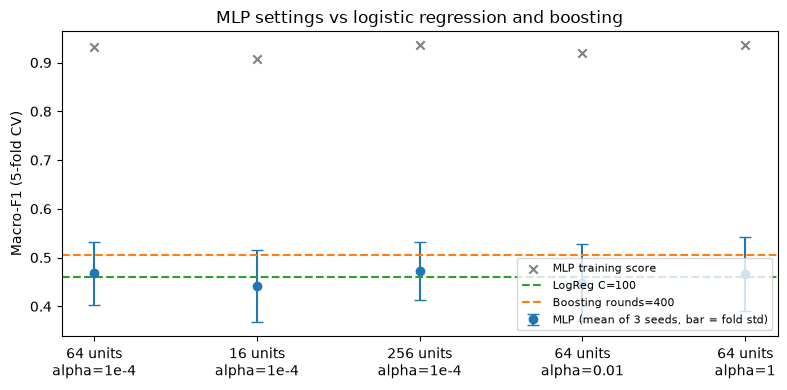

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
pos = np.arange(len(mlp_table))
ax.errorbar(pos, mlp_table["macro_f1"], yerr=mlp_table["fold_std"], fmt="o", capsize=4,
            label="MLP (mean of 3 seeds, bar = fold std)")
ax.scatter(pos, mlp_table["train_macro_f1"], marker="x", color="grey", label="MLP training score")
for _, row in reference.iterrows():
    ax.axhline(row["macro_f1"], linestyle="--", color="tab:orange" if "Boost" in row["model"] else "tab:green",
               label=row["model"])
ax.set_xticks(pos)
ax.set_xticklabels(mlp_table["model"].str.replace("MLP ", "").str.replace(", ", "\n"))
ax.set_ylabel("Macro-F1 (5-fold CV)")
ax.set_title("MLP settings vs logistic regression and boosting")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "mlp_settings.png", dpi=150)
plt.show()

## Learning curves

For each trained network, `loss_curve_` is the training loss after each epoch and `validation_scores_` is the accuracy on the 10% early-stopping hold-out. The curves below are for the first setting (64 units, `alpha=1e-4`), seed 0, one line per fold.
If the training loss keeps falling while the validation accuracy flattens or drops, the network is overfitting; early stopping ends training at that point.

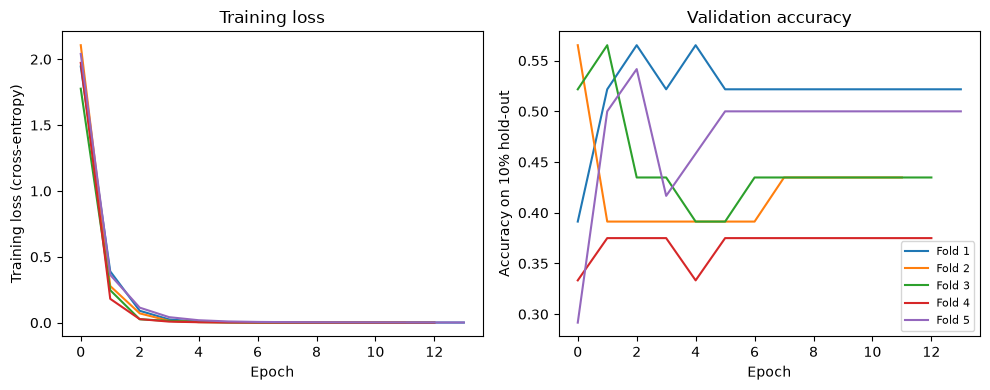

,fold,epochs,best_holdout_accuracy,final_training_loss
0,1,14,0.565,0.0011
1,2,12,0.565,0.0010
2,3,13,0.565,0.0008
3,4,13,0.375,0.0008
4,5,14,0.542,0.0019


In [7]:
nets = [pipe[-1] for pipe in mlp_results[0]["estimators"][:5]]  # seed 0, folds 1-5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for fold, net in enumerate(nets, start=1):
    ax1.plot(net.loss_curve_, label=f"Fold {fold}")
    ax2.plot(net.validation_scores_, label=f"Fold {fold}")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Training loss (cross-entropy)"); ax1.set_title("Training loss")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy on 10% hold-out"); ax2.set_title("Validation accuracy")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "mlp_learning_curves.png", dpi=150)
plt.show()

pd.DataFrame({"fold": range(1, 6),
              "epochs": [net.n_iter_ for net in nets],
              "best_holdout_accuracy": [round(net.best_validation_score_, 3) for net in nets],
              "final_training_loss": [round(net.loss_curve_[-1], 4) for net in nets]})

**Findings:** all five settings score 0.44–0.47 macro-F1, and the differences between them are smaller than both the fold spread (about ±0.07) and the seed spread (up to ±0.04). The 256-unit network has the best mean (0.472) and the smallest seed spread, but takes about 3× longer to train than 64 units for +0.005.

Every setting overfits heavily: about 0.93 macro-F1 on the training books but about 0.46 on new authors. The learning curves agree: training loss falls to about 0.001 within a few epochs, and every fold stops after 12–14 epochs, so the best hold-out score was reached at around epoch 2–4 (early stopping waits 10 epochs without improvement). The hold-out is only about 23 books, so its accuracy jumps in steps of about 0.04 (fold 4: 0.375).

Raising `alpha` to 1 did not reduce the training score, so the penalty is still too weak to matter. Much stronger values are tested below.

In [8]:
for alpha in [10.0, 100.0]:
    name = f"MLP 64 units, alpha={alpha:g}"
    start = time.time()
    mlp_results.append(evaluate_seeds(name, mlp(alpha=alpha)))
    print(f"{name}: {time.time() - start:.0f} s")

mlp_table = pd.DataFrame(mlp_results).drop(columns="estimators")
mlp_table.round(3)

MLP 64 units, alpha=10: 139 s
MLP 64 units, alpha=100: 118 s


,model,macro_f1,fold_std,seed_std,train_macro_f1,accuracy,fit_time_s,seed_macro_f1
0,"MLP 64 units, alpha=1e-4",0.467,0.065,0.026,0.933,0.474,5.558,"[0.46, 0.44, 0.503]"
1,"MLP 16 units, alpha=1e-4",0.442,0.074,0.041,0.907,0.448,2.055,"[0.455, 0.386, 0.483]"
2,"MLP 256 units, alpha=1e-4",0.472,0.059,0.010,0.936,0.496,17.077,"[0.481, 0.458, 0.477]"
3,"MLP 64 units, alpha=0.01",0.449,0.079,0.035,0.919,0.458,5.518,"[0.415, 0.434, 0.496]"
4,"MLP 64 units, alpha=1",0.465,0.076,0.031,0.935,0.476,6.085,"[0.422, 0.478, 0.496]"
5,"MLP 64 units, alpha=10",0.528,0.051,0.011,0.964,0.535,7.781,"[0.533, 0.513, 0.539]"
6,"MLP 64 units, alpha=100",0.491,0.065,0.052,0.959,0.514,6.385,"[0.419, 0.513, 0.541]"


In [9]:
mlp_table.to_csv(config.ROOT / "reports" / "mlp_results.csv", index=False)
print("Saved", len(mlp_table), "MLP runs")

Saved 7 MLP runs


**Stronger regularisation:** `alpha=10` gives the best MLP: macro-F1 0.528 ± 0.051, with the smallest seed spread (0.51–0.54 across seeds). Performance falls again at `alpha=100` (too much penalty). This is 0.022 above boosting (0.506), less than one fold standard deviation. It was also chosen as the best of 7 settings on the same folds, so its score is probably slightly optimistic. The training score did not fall (0.964), so the penalty does not simply stop memorisation; it seems to make the network learn more general patterns before early stopping ends training.

To check whether the gap is consistent, the MLP is compared with boosting and logistic regression fold by fold (all three use exactly the same 5 folds).

In [10]:
import json
from sklearn.metrics import f1_score

folds = list(cv.split(X, y, groups))
best = next(r for r in mlp_results if r["model"] == "MLP 64 units, alpha=10")
# Score every stored network (3 seeds x 5 folds) on its own validation fold
fold_scores = np.zeros((len(SEEDS), len(folds)))
for i, pipe in enumerate(best["estimators"]):
    seed, k = divmod(i, len(folds))
    _, val = folds[k]
    fold_scores[seed, k] = f1_score(y.iloc[val], pipe.predict(X.iloc[val]), average="macro")
print("Check, seed means:", fold_scores.mean(axis=1).round(3))  # should match seed_macro_f1

ref_folds = {row["model"]: json.loads(row["fold_macro_f1"]) for _, row in reference.iterrows()}
paired = pd.DataFrame({
    "fold": range(1, 6),
    "MLP alpha=10 (mean of 3 seeds)": fold_scores.mean(axis=0).round(3),
    "Boosting": ref_folds["Boosting rounds=400"],
    "LogReg": ref_folds["LogReg C=100"],
})
paired["MLP - Boosting"] = (paired["MLP alpha=10 (mean of 3 seeds)"] - paired["Boosting"]).round(3)
paired["MLP - LogReg"] = (paired["MLP alpha=10 (mean of 3 seeds)"] - paired["LogReg"]).round(3)

print("MLP beats boosting on", (paired["MLP - Boosting"] > 0).sum(), "of 5 folds,",
      "mean difference", paired["MLP - Boosting"].mean().round(3))
print("MLP beats LogReg on", (paired["MLP - LogReg"] > 0).sum(), "of 5 folds,",
      "mean difference", paired["MLP - LogReg"].mean().round(3))
paired

Check, seed means: [0.533 0.513 0.539]
MLP beats boosting on 3 of 5 folds, mean difference 0.023
MLP beats LogReg on 4 of 5 folds, mean difference 0.069


,fold,MLP alpha=10 (mean of 3 seeds),Boosting,LogReg,MLP - Boosting,MLP - LogReg
0,1,0.563,0.482,0.412,0.081,0.151
1,2,0.504,0.433,0.378,0.071,0.126
2,3,0.491,0.493,0.440,-0.002,0.051
3,4,0.500,0.495,0.567,0.005,-0.067
4,5,0.584,0.625,0.502,-0.041,0.082


## Comparison with logistic regression and boosting

Fold by fold, the best MLP (`alpha=10`) beats logistic regression on 4 of 5 folds (+0.069 on average), a consistent improvement. Against boosting the picture is mixed: it is clearly better on folds 1 and 2, clearly worse on fold 5, and the other two folds are ties. Its +0.023 average lead is smaller than one fold standard deviation and comes from picking the best of 7 settings, so it is probably partly luck.

In [11]:
pipe = best["estimators"][0]
net = pipe[-1]
vocab = len(pipe[0].vocabulary_)
n_weights = sum(w.size for w in net.coefs_) + sum(b.size for b in net.intercepts_)
print(f"Input words: {vocab}, hidden units: 64, outputs: 5 -> {n_weights:,} weights")

# Training times depend on how busy the computer is, so LR and boosting are re-timed here,
# in the same session as the MLP, instead of using notebook 03's times.
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

timed = {
    "LogReg C=100": make_pipeline(tfidf(), LogisticRegression(C=100, max_iter=2000)),
    "Boosting rounds=400": make_pipeline(tfidf(), GradientBoostingClassifier(
        n_estimators=400, learning_rate=0.1, max_depth=3, max_features="sqrt", random_state=config.RANDOM_STATE)),
}
fit_time = {name: cross_validate(m, X, y, groups=groups, cv=cv)["fit_time"].mean() for name, m in timed.items()}

lr, gb = reference.set_index("model").loc[["LogReg C=100", "Boosting rounds=400"]].to_dict("index").values()
mlp_best = mlp_table.set_index("model").loc["MLP 64 units, alpha=10"]
pd.DataFrame({
    "model": ["Logistic regression (C=100)", "Gradient boosting (400 rounds)", "MLP 64 units, alpha=10"],
    "macro_f1": [lr["macro_f1"], gb["macro_f1"], mlp_best["macro_f1"]],
    "fold_std": [lr["macro_f1_std"], gb["macro_f1_std"], mlp_best["fold_std"]],
    "fit_time_s_per_fold": [fit_time["LogReg C=100"], fit_time["Boosting rounds=400"], mlp_best["fit_time_s"]],
    "size": ["5 x 6,024 weights", "400 rounds x 5 trees of depth 3", f"{n_weights:,} weights"],
}).round(3)

Input words: 6024, hidden units: 64, outputs: 5 -> 385,925 weights


,model,macro_f1,fold_std,fit_time_s_per_fold,size
0,Logistic regression (C=100),0.460,0.067,3.168,"5 x 6,024 weights"
1,Gradient boosting (400 rounds),0.506,0.064,9.917,400 rounds x 5 trees of depth 3
2,"MLP 64 units, alpha=10",0.528,0.051,7.781,"385,925 weights"


## Conclusion: is the MLP justified?

**Partly.** A small MLP with strong regularisation (`alpha=10`) reaches 0.528 ± 0.051 macro-F1, comparable to gradient boosting (0.506 ± 0.064) and clearly better than logistic regression (0.460), and one network trains in about the same time as boosting (table above, timed in the same session). However:
- it only works well with an L2 penalty 100,000× the default; at the default settings it is no better than logistic regression;
- results depend on the random seed (seed spread up to ±0.05 for other settings), so 3 seeds are needed to report it fairly, which triples its training cost;
- it still overfits heavily (training score 0.96 vs 0.53 on new authors) and memorises the training books within a few epochs;
- its 385,925 weights are much harder to interpret than logistic regression coefficients or tree feature importances.

**Decision:** gradient boosting stays the preferred model. The MLP is not consistently better across folds, and boosting has already had its single test-set evaluation (notebook 03). Testing the MLP as well would mean choosing between models after seeing test scores. The MLP is therefore reported with cross-validation results only (experiments E16–E20 in `reports/experiment_log.md`).